<a href="https://colab.research.google.com/github/putriekasfr/24-052_24-087_TugasCNN_PraktikumB/blob/main/24_087_Bagian_C_ObjectDetection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bagian C - Object Detection I (Penn-Fudan + Faster R-CNN)
**NAMA : PUTRI EKA SAFIRA**
**NIM : 240441100087**

In [ ]:
!pip install -q torchmetrics pycocotools
!wget -q https://www.cis.upenn.edu/~jshi/ped_html/PennFudanPed.zip
!unzip -q -o PennFudanPed.zip
!ls PennFudanPed

added-object-list.txt  Annotation  PedMasks  PNGImages	readme.txt


In [ ]:
import os, time, random
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.patches as patches
import torch, torchvision
import torchvision.ops as tvo
from torchvision.io import read_image
from torchvision.ops import masks_to_boxes
from torchvision.models.detection import fasterrcnn_resnet50_fpn, FasterRCNN_ResNet50_FPN_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchmetrics.detection import MeanAveragePrecision

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(torch.__version__, torchvision.__version__, device)

2.11.0+cu130 0.26.0+cu130 cuda


## Dataset, augmentasi, dan pembagian 120/50 (seed 42)

In [ ]:
class PennFudan(torch.utils.data.Dataset):
    def __init__(self, root, transforms=None):
        self.root, self.transforms = root, transforms
        self.imgs  = sorted(os.listdir(os.path.join(root, "PNGImages")))
        self.masks = sorted(os.listdir(os.path.join(root, "PedMasks")))
    def __len__(self):
        return len(self.imgs)
    def __getitem__(self, i):
        img = read_image(os.path.join(self.root, "PNGImages", self.imgs[i]))
        img = img.float() / 255
        mask = read_image(os.path.join(self.root, "PedMasks", self.masks[i]))[0]
        ids = mask.unique()[1:]                         # buang 0 (latar)
        masks = (mask[None] == ids[:, None, None])
        boxes = masks_to_boxes(masks).float()           # format xyxy
        target = {"boxes": boxes, "labels": torch.ones(len(ids), dtype=torch.int64)}
        if self.transforms:
            img, target = self.transforms(img, target)
        return img, target

collate = lambda batch: tuple(zip(*batch))

class RandomHFlip:
    """Flip horizontal p=0.5; kotak ikut di-flip."""
    def __init__(self, p=0.5): self.p = p
    def __call__(self, img, target):
        if torch.rand(1).item() < self.p:
            img = img.flip(-1)
            w = img.shape[-1]
            b = target["boxes"].clone()
            b[:, [0, 2]] = w - target["boxes"][:, [2, 0]]
            target = {**target, "boxes": b}
        return img, target

ROOT = "PennFudanPed"
g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(170, generator=g).tolist()
train_idx, test_idx = perm[:120], perm[120:]

train_ds = torch.utils.data.Subset(PennFudan(ROOT, RandomHFlip(0.5)), train_idx)
test_ds  = torch.utils.data.Subset(PennFudan(ROOT, None), test_idx)
train_loader = torch.utils.data.DataLoader(train_ds, batch_size=2, shuffle=True, collate_fn=collate)
test_gts = [test_ds[i][1] for i in range(len(test_ds))]
print(len(train_ds), len(test_ds), "| rata-rata orang/citra (uji):",
      np.mean([len(t["boxes"]) for t in test_gts]))

120 50 | rata-rata orang/citra (uji): 2.26


---
# C1 - Implementasi dari nol

In [ ]:
def box_iou(a, b):
    """a:(N,4), b:(M,4) format xyxy -> IoU (N,M)."""
    a = np.asarray(a, dtype=np.float64).reshape(-1, 4)
    b = np.asarray(b, dtype=np.float64).reshape(-1, 4)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    lt = np.maximum(a[:, None, :2], b[None, :, :2])
    rb = np.minimum(a[:, None, 2:], b[None, :, 2:])
    wh = np.clip(rb - lt, 0, None)
    inter = wh[..., 0] * wh[..., 1]
    union = area_a[:, None] + area_b[None, :] - inter
    return inter / np.where(union > 0, union, 1.0)

def nms(boxes, scores, tau):
    """NMS greedy: hapus kotak dengan IoU > tau. Return indeks (skor turun)."""
    boxes = np.asarray(boxes, dtype=np.float64)
    order = np.argsort(-np.asarray(scores, dtype=np.float64), kind="stable")
    keep = []
    while order.size:
        i = order[0]; keep.append(int(i))
        if order.size == 1: break
        iou = box_iou(boxes[i:i+1], boxes[order[1:]])[0]
        order = order[1:][iou <= tau]
    return np.array(keep, dtype=np.int64)

def average_precision(tp, num_gt, mode="all"):
    """tp: array 0/1 terurut skor turun. mode 'all' (VOC2010+) atau '11' (VOC2007)."""
    tp = np.asarray(tp, dtype=np.float64)
    ctp, cfp = np.cumsum(tp), np.cumsum(1 - tp)
    rec, prec = ctp / num_gt, ctp / (ctp + cfp)
    if mode == "11":
        ap = 0.0
        for t in np.arange(0, 1.1, 0.1):
            m = rec >= t - 1e-12
            ap += (prec[m].max() if m.any() else 0.0) / 11
        return ap, prec, rec
    mrec = np.concatenate(([0.0], rec, [1.0])); mpre = np.concatenate(([0.0], prec, [0.0]))
    for i in range(len(mpre) - 2, -1, -1):
        mpre[i] = max(mpre[i], mpre[i + 1])
    idx = np.where(mrec[1:] != mrec[:-1])[0]
    return float(np.sum((mrec[idx + 1] - mrec[idx]) * mpre[idx + 1])), prec, rec

def match_detections(dets, thr):
    """dets: (nama, skor, citra, gt, iou) -> flag TP(1)/FP(0), greedy."""
    taken, flags = set(), []
    for _, _, img, gt, iou in sorted(dets, key=lambda d: -d[1]):
        if gt is not None and iou >= thr and (img, gt) not in taken:
            taken.add((img, gt)); flags.append(1)
        else:
            flags.append(0)
    return np.array(flags)

### C1.2 Verifikasi terhadap `torchvision.ops` (1.000 kotak acak)

In [ ]:
rng = np.random.default_rng(42)
xy = rng.uniform(0, 500, (1000, 2)); wh = rng.uniform(10, 200, (1000, 2))
bx = np.concatenate([xy, xy + wh], 1).astype(np.float32)
sc = rng.uniform(0, 1, 1000).astype(np.float32)

ours = box_iou(bx, bx)
ref = tvo.box_iou(torch.from_numpy(bx), torch.from_numpy(bx)).numpy()
print(f"Selisih maksimum IoU: {np.abs(ours - ref).max():.3e}")
rows = []
for tau in (0.3, 0.5, 0.7):
    k1 = nms(bx, sc, tau)
    k2 = tvo.nms(torch.from_numpy(bx), torch.from_numpy(sc), tau).numpy()
    rows.append({"tau": tau, "keep_ours": len(k1), "keep_torchvision": len(k2),
                 "indeks identik": bool(np.array_equal(k1, k2))})
pd.DataFrame(rows)

Selisih maksimum IoU: 1.748e-07


,tau,keep_ours,keep_torchvision,indeks identik
0,0.3,323,323,True
1,0.5,636,636,True
2,0.7,920,920,True


### C1.3 Jalankan pada data B4 dan B5 (bandingkan dengan hitungan manual)

In [ ]:
names = ["P1","P2","P3","P4","P5","P6"]
B = np.array([[100,100,200,220],[110,95,210,230],[125,120,225,240],
              [160,110,270,230],[400,50,480,170],[405,60,490,165]], float)
S = np.array([0.93,0.89,0.80,0.76,0.70,0.42])
M = box_iou(B, B)
for a, b in [(0,1),(0,2),(0,3),(1,2),(1,3),(2,3),(4,5)]:
    print(f"IoU {names[a]}-{names[b]} = {M[a,b]:.4f}")
for tau in (0.3, 0.5, 0.8):
    print(f"NMS tau={tau}:", [names[i] for i in nms(B, S, tau)])
m = S >= 0.5
print("Skor>=0,5 lalu NMS tau=0,8:", [names[i] for i in np.where(m)[0][nms(B[m], S[m], 0.8)]])

D = [("D1",.96,1,"G1",.82),("D2",.92,2,"G3",.71),("D3",.89,1,"G1",.64),("D4",.85,3,"G6",.58),
     ("D5",.81,2,"G4",.43),("D6",.77,2,"G5",.90),("D7",.70,1,None,.00),("D8",.63,2,"G4",.55),
     ("D9",.52,3,"G6",.51),("D10",.40,1,"G2",.47)]
for thr in (0.5, 0.75):
    fl = match_detections(D, thr)
    ap_all, p, r = average_precision(fl, 6, "all"); ap_11, _, _ = average_precision(fl, 6, "11")
    print(f"\nIoU {thr}: {['TP' if f else 'FP' for f in fl]}")
    print("precision:", np.round(p, 4)); print("recall   :", np.round(r, 4))
    print(f"AP all-point = {ap_all:.4f} | AP 11-point = {ap_11:.4f} | recall maks = {r.max():.4f}")

IoU P1-P2 = 0.7347
IoU P1-P3 = 0.4545
IoU P1-P4 = 0.2115
IoU P2-P3 = 0.5789
IoU P2-P4 = 0.2899
IoU P3-P4 = 0.3961
IoU P5-P6 = 0.7394
NMS tau=0.3: ['P1', 'P4', 'P5']
NMS tau=0.5: ['P1', 'P3', 'P4', 'P5']
NMS tau=0.8: ['P1', 'P2', 'P3', 'P4', 'P5', 'P6']
Skor>=0,5 lalu NMS tau=0,8: ['P1', 'P2', 'P3', 'P4', 'P5']

IoU 0.5: ['TP', 'TP', 'FP', 'TP', 'FP', 'TP', 'FP', 'TP', 'FP', 'FP']
precision: [1.     1.     0.6667 0.75   0.6    0.6667 0.5714 0.625  0.5556 0.5   ]
recall   : [0.1667 0.3333 0.3333 0.5    0.5    0.6667 0.6667 0.8333 0.8333 0.8333]
AP all-point = 0.6736 | AP 11-point = 0.6742 | recall maks = 0.8333

IoU 0.75: ['TP', 'FP', 'FP', 'FP', 'FP', 'TP', 'FP', 'FP', 'FP', 'FP']
precision: [1.     0.5    0.3333 0.25   0.2    0.3333 0.2857 0.25   0.2222 0.2   ]
recall   : [0.1667 0.1667 0.1667 0.1667 0.1667 0.3333 0.3333 0.3333 0.3333 0.3333]
AP all-point = 0.2222 | AP 11-point = 0.2424 | recall maks = 0.3333


---
# C2 - Fine-tuning Faster R-CNN

In [ ]:
def build_model():
    m = fasterrcnn_resnet50_fpn(weights=FasterRCNN_ResNet50_FPN_Weights.DEFAULT)
    in_f = m.roi_heads.box_predictor.cls_score.in_features
    m.roi_heads.box_predictor = FastRCNNPredictor(in_f, 2)   # latar + orang
    return m

LOSS_KEYS = ["loss_classifier", "loss_box_reg", "loss_objectness", "loss_rpn_box_reg"]

def train_one_epoch(model, loader, opt):
    model.train()
    sums, n = {k: 0.0 for k in LOSS_KEYS}, 0
    for imgs, tg in loader:
        imgs = [i.to(device) for i in imgs]
        tg = [{k: v.to(device) for k, v in t.items()} for t in tg]
        ld = model(imgs, tg)
        loss = sum(ld.values())
        opt.zero_grad(); loss.backward(); opt.step()
        for k in LOSS_KEYS: sums[k] += ld[k].item()
        n += 1
    return {k: sums[k] / n for k in LOSS_KEYS}

model = build_model().to(device)
params = [p for p in model.parameters() if p.requires_grad]
opt = torch.optim.SGD(params, lr=0.005, momentum=0.9, weight_decay=5e-4)
sched = torch.optim.lr_scheduler.StepLR(opt, step_size=3, gamma=0.1)

history = []
for ep in range(10):
    t0 = time.time()
    h = train_one_epoch(model, train_loader, opt); sched.step()
    history.append(h)
    print(f"epoch {ep+1:2d} | " + " | ".join(f"{k[5:]}={v:.4f}" for k, v in h.items()) + f" | {time.time()-t0:.0f}s")
hist = pd.DataFrame(history, index=range(1, 11)); hist

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:02<00:00, 65.0MB/s]


epoch  1 | classifier=0.0809 | box_reg=0.1697 | objectness=0.0050 | rpn_box_reg=0.0066 | 49s
epoch  2 | classifier=0.0373 | box_reg=0.0880 | objectness=0.0020 | rpn_box_reg=0.0055 | 43s
epoch  3 | classifier=0.0327 | box_reg=0.0650 | objectness=0.0005 | rpn_box_reg=0.0041 | 47s
epoch  4 | classifier=0.0285 | box_reg=0.0495 | objectness=0.0009 | rpn_box_reg=0.0033 | 45s
epoch  5 | classifier=0.0258 | box_reg=0.0416 | objectness=0.0007 | rpn_box_reg=0.0028 | 46s
epoch  6 | classifier=0.0256 | box_reg=0.0403 | objectness=0.0008 | rpn_box_reg=0.0026 | 45s
epoch  7 | classifier=0.0255 | box_reg=0.0397 | objectness=0.0006 | rpn_box_reg=0.0028 | 45s
epoch  8 | classifier=0.0253 | box_reg=0.0380 | objectness=0.0004 | rpn_box_reg=0.0027 | 46s
epoch  9 | classifier=0.0257 | box_reg=0.0370 | objectness=0.0009 | rpn_box_reg=0.0025 | 45s
epoch 10 | classifier=0.0239 | box_reg=0.0375 | objectness=0.0010 | rpn_box_reg=0.0025 | 46s


,loss_classifier,loss_box_reg,loss_objectness,loss_rpn_box_reg
1,0.080902,0.169676,0.004955,0.006587
2,0.037341,0.088044,0.002033,0.005468
3,0.032684,0.064975,0.000487,0.004063
4,0.028476,0.049508,0.000918,0.003312
5,0.025843,0.041617,0.000739,0.002792
6,0.025570,0.040268,0.000809,0.002646
7,0.025461,0.039696,0.000561,0.002784
8,0.025301,0.038046,0.000382,0.002675
9,0.025669,0.037000,0.000855,0.002523
10,0.023911,0.037501,0.001036,0.002524


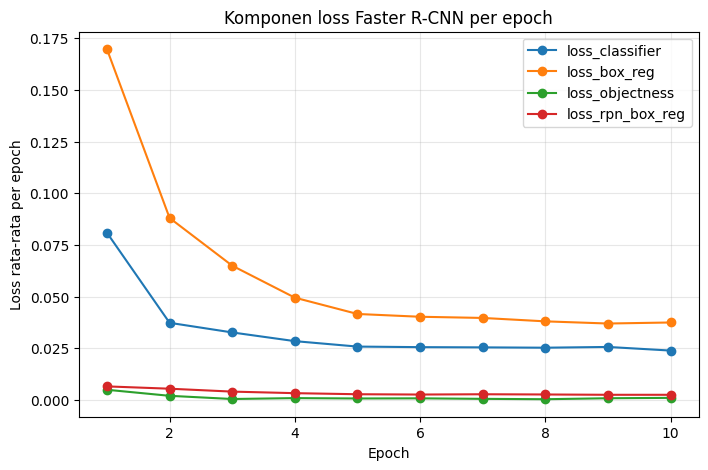

,epoch1,epoch10,turun (%)
loss_classifier,0.0809,0.0239,70.4443
loss_box_reg,0.1697,0.0375,77.8987
loss_objectness,0.0050,0.0010,79.0998
loss_rpn_box_reg,0.0066,0.0025,61.6813


In [ ]:
# (a) keempat komponen loss dalam satu gambar
plt.figure(figsize=(8, 5))
for k in LOSS_KEYS:
    plt.plot(hist.index, hist[k], marker="o", label=k)
plt.xlabel("Epoch"); plt.ylabel("Loss rata-rata per epoch")
plt.title("Komponen loss Faster R-CNN per epoch"); plt.legend(); plt.grid(alpha=.3)
plt.savefig("c2_loss.png", dpi=150, bbox_inches="tight"); plt.show()

# turun relatif epoch 1 -> 10 (bahan untuk poin c)
pd.DataFrame({"epoch1": hist.iloc[0], "epoch10": hist.iloc[-1],
              "turun (%)": (1 - hist.iloc[-1] / hist.iloc[0]) * 100}).round(4)

In [ ]:
def run_inference(model, ds, warmup=2):
    """Batch 1. Return (daftar output di CPU, rata-rata detik per citra)."""
    model.eval(); outs, times = [], []
    with torch.no_grad():
        for i in range(min(warmup, len(ds))):
            model([ds[i][0].to(device)])
        for i in range(len(ds)):
            img = ds[i][0].to(device)
            if device.type == "cuda": torch.cuda.synchronize()
            t0 = time.perf_counter()
            o = model([img])[0]
            if device.type == "cuda": torch.cuda.synchronize()
            times.append(time.perf_counter() - t0)
            outs.append({k: v.cpu() for k, v in o.items()})
    return outs, float(np.mean(times))

def compute_map(outs, gts):
    metric = MeanAveragePrecision(iou_type="bbox")
    metric.update([{"boxes": o["boxes"], "scores": o["scores"], "labels": o["labels"]} for o in outs],
                  [{"boxes": t["boxes"], "labels": t["labels"]} for t in gts])
    r = metric.compute()
    return r["map"].item(), r["map_50"].item(), r["map_75"].item()

# (b) evaluasi setelah epoch terakhir
outs_ft, _ = run_inference(model, test_ds)
ap, ap50, ap75 = compute_map(outs_ft, test_gts)
res_c2 = pd.DataFrame([{"AP": ap, "AP50": ap50, "AP75": ap75}]).round(4); res_c2

,AP,AP50,AP75
0,0.8174,0.9906,0.9518


### C2(c) Draf penjelasan

In [ ]:
absdrop = hist.iloc[0] - hist.iloc[-1]
reldrop = (1 - hist.iloc[-1] / hist.iloc[0]) * 100
fastest = reldrop.idxmax(); biggest_abs = absdrop.idxmax(); start_high = hist.iloc[0].idxmax()

why = {
 "loss_classifier": "Head klasifikasi (box_predictor) diganti menjadi 2 kelas dan diinisialisasi acak, sehingga awalnya paling salah dan paling banyak yang harus dipelajari. Backbone, FPN, dan RPN sudah membawa fitur COCO yang bagus untuk 'person', jadi hanya lapisan klasifikasi baru yang perlu menyesuaikan, dan itu bisa dipelajari cepat.",
 "loss_box_reg": "Regresi kotak menyesuaikan diri dengan gaya anotasi Penn-Fudan, yaitu kotak yang ketat karena diturunkan dari mask instans, berbeda dari kotak COCO. Penyesuaian ini besar di awal lalu cepat mendekati gaya anotasi yang baru.",
 "loss_objectness": "RPN dari COCO sudah bisa membedakan objek dan latar, tetapi domain Penn-Fudan (pejalan kaki di jalan dan kampus) berbeda, sehingga objectness cepat menyesuaikan pada beberapa epoch pertama.",
 "loss_rpn_box_reg": "Regresi anchor di RPN menyesuaikan ke skala dan bentuk pejalan kaki di dataset ini, dan cepat turun begitu anchor belajar bentuk orang berdiri (tinggi lebih besar dari lebar).",
}
print(f"Komponen yang turun paling cepat (relatif, epoch 1 ke 10): {fastest} ({reldrop[fastest]:.1f}%)")
print(f"Komponen dengan penurunan absolut terbesar: {biggest_abs} ({absdrop[biggest_abs]:.4f})")
print(f"Komponen dengan nilai awal terbesar: {start_high} ({hist.iloc[0][start_high]:.4f})")
print("\nPenjelasan:", why[fastest])
print("\nCatatan: loss_rpn_box_reg dan loss_objectness biasanya sudah kecil sejak awal karena RPN COCO sudah bagus,")
print("jadi penurunan absolutnya kecil. Bandingkan dengan angka di tabel 'turun (%)' sebelum menulis kesimpulan akhir.")
print("Total loss per epoch:", hist.sum(axis=1).round(4).tolist())
print("StepLR menurunkan lr (x0,1) tiap 3 epoch, jadi cek apakah ada penurunan tambahan setelah epoch 3, 6, dan 9.")

Komponen yang turun paling cepat (relatif, epoch 1 ke 10): loss_objectness (79.1%)
Komponen dengan penurunan absolut terbesar: loss_box_reg (0.1322)
Komponen dengan nilai awal terbesar: loss_box_reg (0.1697)

Penjelasan: RPN dari COCO sudah bisa membedakan objek dan latar, tetapi domain Penn-Fudan (pejalan kaki di jalan dan kampus) berbeda, sehingga objectness cepat menyesuaikan pada beberapa epoch pertama.

Catatan: loss_rpn_box_reg dan loss_objectness biasanya sudah kecil sejak awal karena RPN COCO sudah bagus,
jadi penurunan absolutnya kecil. Bandingkan dengan angka di tabel 'turun (%)' sebelum menulis kesimpulan akhir.
Total loss per epoch: [0.2621, 0.1329, 0.1022, 0.0822, 0.071, 0.0693, 0.0685, 0.0664, 0.066, 0.065]
StepLR menurunkan lr (x0,1) tiap 3 epoch, jadi cek apakah ada penurunan tambahan setelah epoch 3, 6, dan 9.


---
# C3 - Ablasi saat inferensi (tanpa melatih ulang)

In [ ]:
orig_nms = model.roi_heads.nms_thresh
orig_post = model.rpn._post_nms_top_n["testing"]

# --- Tabel 1: roi_heads.nms_thresh
rows1 = []
for t in [0.3, 0.5, 0.7, 0.9]:
    model.roi_heads.nms_thresh = t
    outs, _ = run_inference(model, test_ds)
    ap, ap50, _ = compute_map(outs, test_gts)
    rows1.append({"nms_thresh": t, "AP": ap, "AP50": ap50,
                  "rata2 deteksi skor>=0,5/citra": np.mean([(o["scores"] >= 0.5).sum().item() for o in outs])})
model.roi_heads.nms_thresh = orig_nms
t1 = pd.DataFrame(rows1).round(4); display(t1)

# --- Tabel 2: rpn post_nms_top_n (testing)
rows2 = []
for n in [10, 50, 300, 1000]:
    model.rpn._post_nms_top_n["testing"] = n
    outs, sec = run_inference(model, test_ds)
    ap, ap50, _ = compute_map(outs, test_gts)
    rows2.append({"post_nms_top_n": n, "AP": ap, "AP50": ap50, "waktu/citra (ms)": sec * 1000})
model.rpn._post_nms_top_n["testing"] = orig_post
t2 = pd.DataFrame(rows2).round(4); display(t2)

,nms_thresh,AP,AP50,"rata2 deteksi skor>=0,5/citra"
0,0.3,0.8094,0.9811,2.52
1,0.5,0.8174,0.9906,2.64
2,0.7,0.8177,0.9880,3.04
3,0.9,0.7952,0.9470,8.90


,post_nms_top_n,AP,AP50,waktu/citra (ms)
0,10,0.8022,0.9566,138.7645
1,50,0.8232,0.9906,139.1889
2,300,0.8171,0.9906,143.4134
3,1000,0.8174,0.9906,150.0637


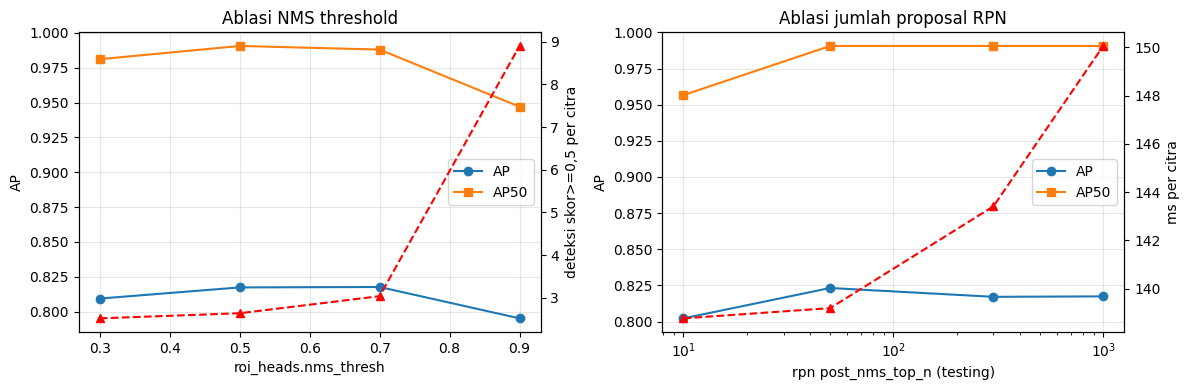

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(t1["nms_thresh"], t1["AP"], "o-", label="AP"); ax[0].plot(t1["nms_thresh"], t1["AP50"], "s-", label="AP50")
ax[0].set_xlabel("roi_heads.nms_thresh"); ax[0].set_ylabel("AP"); ax[0].grid(alpha=.3); ax[0].legend()
a2 = ax[0].twinx(); a2.plot(t1["nms_thresh"], t1.iloc[:, 3], "r--^", label="deteksi/citra"); a2.set_ylabel("deteksi skor>=0,5 per citra")
ax[0].set_title("Ablasi NMS threshold")

ax[1].plot(t2["post_nms_top_n"], t2["AP"], "o-", label="AP"); ax[1].plot(t2["post_nms_top_n"], t2["AP50"], "s-", label="AP50")
ax[1].set_xscale("log"); ax[1].set_xlabel("rpn post_nms_top_n (testing)"); ax[1].set_ylabel("AP"); ax[1].grid(alpha=.3); ax[1].legend()
b2 = ax[1].twinx(); b2.plot(t2["post_nms_top_n"], t2["waktu/citra (ms)"], "r--^"); b2.set_ylabel("ms per citra")
ax[1].set_title("Ablasi jumlah proposal RPN")
plt.tight_layout(); plt.savefig("c3_ablasi.png", dpi=150); plt.show()

### C3 Draf penjelasan (otomatis dari hasilmu)

In [ ]:
mean_gt = np.mean([len(t["boxes"]) for t in test_gts])
col_det = t1.columns[3]
best1 = t1.loc[t1["AP"].idxmax()]
print(f"Rata-rata orang (GT) per citra uji: {mean_gt:.2f}")
print(f"\n[nms_thresh] AP tertinggi di {best1['nms_thresh']} (AP={best1['AP']:.4f}, AP50={best1['AP50']:.4f}, deteksi/citra={best1[col_det]:.2f})")
for _, r in t1.iterrows():
    sel = "lebih banyak" if r[col_det] > mean_gt else "kurang lebih sama atau lebih sedikit"
    print(f"  tau={r['nms_thresh']}: {r[col_det]:.2f} deteksi/citra ({sel} daripada {mean_gt:.2f} orang sebenarnya)")
print("Tafsir: nms_thresh rendah menghapus kotak yang tumpang-tindih, termasuk orang berdempetan (recall turun).")
print("nms_thresh tinggi membiarkan kotak duplikat lolos, jumlah deteksi melewati jumlah orang sebenarnya dan presisi turun.")

mx = t2["AP"].max()
ok = t2[t2["AP"] >= mx - 0.005]
best2 = ok.loc[ok["post_nms_top_n"].idxmin()]
print(f"\n[post_nms_top_n] AP maksimum {mx:.4f}. Nilai terkecil yang AP-nya hampir sama (selisih <= 0,005): {int(best2['post_nms_top_n'])} "
      f"(AP={best2['AP']:.4f}, {best2['waktu/citra (ms)']:.1f} ms/citra)")
slow = t2.loc[t2["post_nms_top_n"].idxmax()]
print(f"Pada {int(slow['post_nms_top_n'])} proposal: AP={slow['AP']:.4f}, {slow['waktu/citra (ms)']:.1f} ms/citra")
print(f"Karena rata-rata hanya sekitar {mean_gt:.1f} orang per citra, proposal berlebih tidak menambah AP tetapi menambah beban head kedua (dan waktu).")
print("Jika AP turun jelas pada nilai sangat kecil (mis. 10), itu tanda orang terlewat karena proposal dipotong terlalu agresif.")

Rata-rata orang (GT) per citra uji: 2.26

[nms_thresh] AP tertinggi di 0.7 (AP=0.8177, AP50=0.9880, deteksi/citra=3.04)
  tau=0.3: 2.52 deteksi/citra (lebih banyak daripada 2.26 orang sebenarnya)
  tau=0.5: 2.64 deteksi/citra (lebih banyak daripada 2.26 orang sebenarnya)
  tau=0.7: 3.04 deteksi/citra (lebih banyak daripada 2.26 orang sebenarnya)
  tau=0.9: 8.90 deteksi/citra (lebih banyak daripada 2.26 orang sebenarnya)
Tafsir: nms_thresh rendah menghapus kotak yang tumpang-tindih, termasuk orang berdempetan (recall turun).
nms_thresh tinggi membiarkan kotak duplikat lolos, jumlah deteksi melewati jumlah orang sebenarnya dan presisi turun.

[post_nms_top_n] AP maksimum 0.8232. Nilai terkecil yang AP-nya hampir sama (selisih <= 0,005): 50 (AP=0.8232, 139.2 ms/citra)
Pada 1000 proposal: AP=0.8174, 150.1 ms/citra
Karena rata-rata hanya sekitar 2.3 orang per citra, proposal berlebih tidak menambah AP tetapi menambah beban head kedua (dan waktu).
Jika AP turun jelas pada nilai sangat kecil 

---
# C4 - Tanpa fine-tuning vs dengan fine-tuning

In [ ]:
coco = fasterrcnn_resnet50_fpn(weights=FasterRCNN_ResNet50_FPN_Weights.DEFAULT).to(device)
outs_coco, _ = run_inference(coco, test_ds)
# pertahankan hanya label 1 (person di COCO)
outs_coco = [{k: v[o["labels"] == 1] for k, v in o.items()} for o in outs_coco]
c_ap, c_ap50, c_ap75 = compute_map(outs_coco, test_gts)

cmp = pd.DataFrame({"COCO tanpa fine-tune": [c_ap, c_ap50, c_ap75],
                    "Fine-tuned (C2)": [res_c2.AP[0], res_c2.AP50[0], res_c2.AP75[0]]},
                   index=["AP", "AP50", "AP75"]).round(4)
cmp["selisih"] = (cmp["Fine-tuned (C2)"] - cmp["COCO tanpa fine-tune"]).round(4); cmp

,COCO tanpa fine-tune,Fine-tuned (C2),selisih
AP,0.7884,0.8174,0.0290
AP50,0.9807,0.9906,0.0099
AP75,0.8837,0.9518,0.0681


### C4 Draf penjelasan

In [ ]:
gain = cmp["selisih"]
top = gain.idxmax()
print(cmp.to_string())
print(f"\nPeningkatan terbesar ada pada {top} ({gain[top]:+.4f}).")
if (gain < 0).any():
    print("Perhatian: ada metrik yang turun setelah fine-tuning: " + ", ".join(gain.index[gain < 0]) + ". Bahas jujur di laporan.")
if top == "AP75":
    print("Interpretasi: peningkatan terbesar di AP75 berarti yang membaik adalah kepasan kotak (lokalisasi), bukan pengenalan orang.")
    print("Ini sesuai dengan gaya anotasi: kotak GT dari mask instans lebih ketat daripada kotak COCO.")
elif top == "AP50":
    print("Interpretasi: peningkatan terbesar di AP50 berarti yang membaik adalah penemuan orang (recall dan precision pada IoU longgar).")
else:
    print("Interpretasi: peningkatan merata pada semua ambang IoU.")
print("""
Alasan model yang sudah kenal 'person' masih bisa membaik:
1. Domain shift: Penn-Fudan punya pose, skala, dan latar tersendiri dibanding COCO.
2. Gaya anotasi: kotak GT diturunkan dari mask instans (ketat), berbeda dari kotak COCO, sehingga regresi kotak perlu disesuaikan.
3. Head diganti menjadi 2 kelas, jadi tidak lagi bersaing dengan 90 kelas COCO lain dan skor 'person' lebih terkalibrasi.
4. Kaitan dengan transfer learning (P9): backbone dan RPN membawa fitur umum dari COCO sehingga tidak dilatih dari nol,
   fine-tuning cukup menyesuaikan lapisan akhir dan sedikit bobot lain ke domain target dengan data kecil (120 citra).
""")

      COCO tanpa fine-tune  Fine-tuned (C2)  selisih
AP                  0.7884           0.8174   0.0290
AP50                0.9807           0.9906   0.0099
AP75                0.8837           0.9518   0.0681

Peningkatan terbesar ada pada AP75 (+0.0681).
Interpretasi: peningkatan terbesar di AP75 berarti yang membaik adalah kepasan kotak (lokalisasi), bukan pengenalan orang.
Ini sesuai dengan gaya anotasi: kotak GT dari mask instans lebih ketat daripada kotak COCO.

Alasan model yang sudah kenal 'person' masih bisa membaik:
1. Domain shift: Penn-Fudan punya pose, skala, dan latar tersendiri dibanding COCO.
2. Gaya anotasi: kotak GT diturunkan dari mask instans (ketat), berbeda dari kotak COCO, sehingga regresi kotak perlu disesuaikan.
3. Head diganti menjadi 2 kelas, jadi tidak lagi bersaing dengan 90 kelas COCO lain dan skor 'person' lebih terkalibrasi.
4. Kaitan dengan transfer learning (P9): backbone dan RPN membawa fitur umum dari COCO sehingga tidak dilatih dari nol,
   fine-t

---
# C5 - Analisis kesalahan (ambang skor 0,5)

In [ ]:
def categorize(outs, gts, thr=0.5):
    counts = {"duplikat": 0, "lokalisasi": 0, "latar": 0, "terlewat": 0, "tp": 0}
    records = []
    for idx, (o, g) in enumerate(zip(outs, gts)):
        keep = o["scores"] >= thr
        pb, ps = o["boxes"][keep], o["scores"][keep]
        pb = pb[ps.argsort(descending=True)]
        gb = g["boxes"]
        iou = tvo.box_iou(pb, gb) if len(pb) and len(gb) else None
        matched, cats = set(), []
        for i in range(len(pb)):
            if iou is None:
                cat = "latar"
            else:
                mx, j = iou[i].max(0); mx, j = mx.item(), j.item()
                if mx >= 0.5:
                    if j in matched: cat = "duplikat"
                    else: matched.add(j); cat = "tp"
                elif mx >= 0.1: cat = "lokalisasi"
                else: cat = "latar"
            counts[cat] += 1; cats.append(cat)
        missed = [j for j in range(len(gb)) if j not in matched]
        counts["terlewat"] += len(missed)
        records.append({"idx": idx, "pb": pb, "cats": cats, "missed": missed, "gb": gb})
    return counts, records

counts, records = categorize(outs_ft, test_gts)
pd.Series(counts, name="jumlah").to_frame()

,jumlah
duplikat,0
lokalisasi,12
latar,8
terlewat,1
tp,112


Kategori yang TIDAK punya contoh pada data uji ini: ['duplikat'] (sebut di laporan; gambar diisi citra lain yang punya kesalahan)


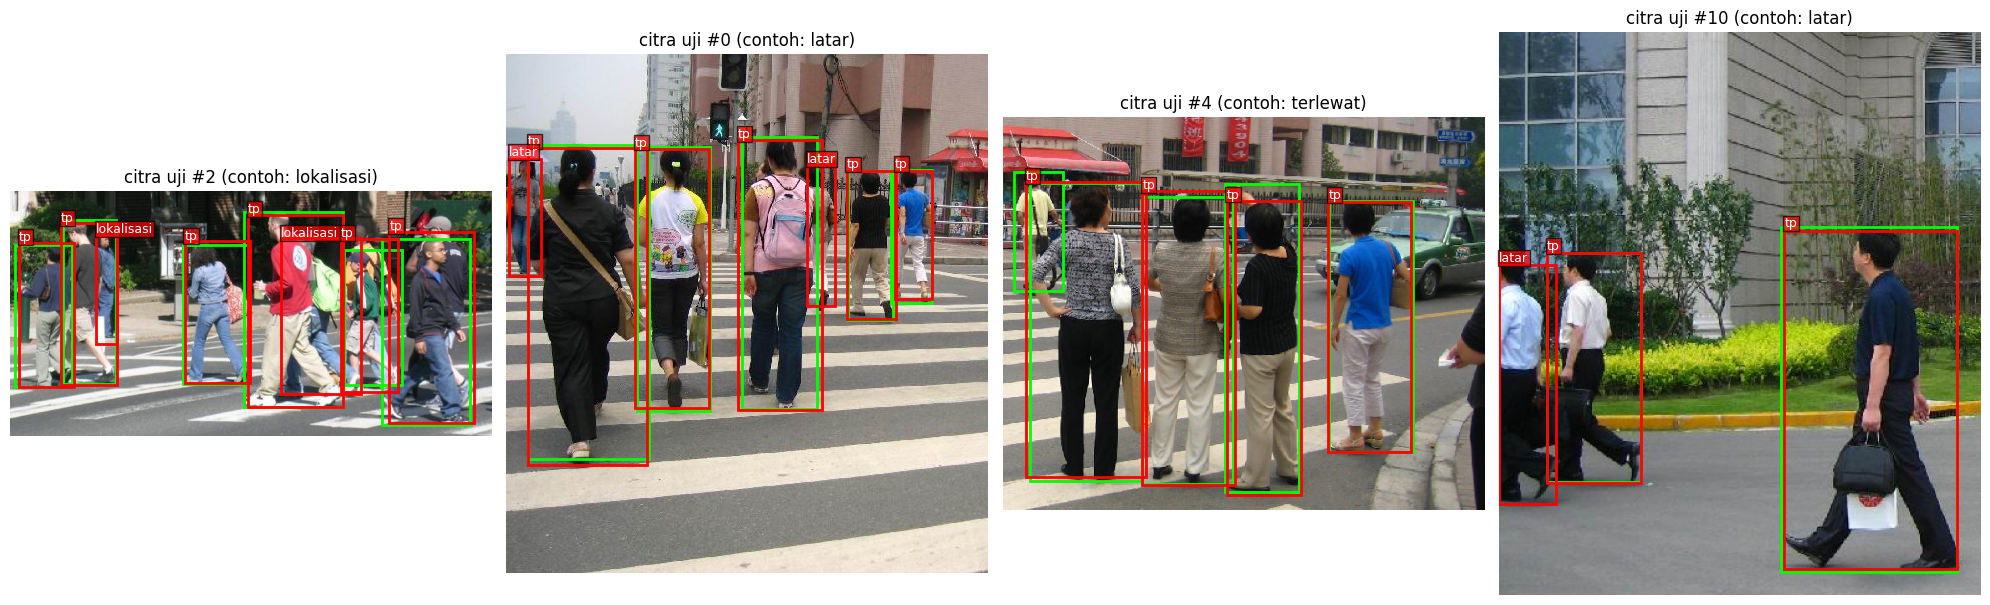

In [ ]:
colors = {"tp": "red", "duplikat": "red", "lokalisasi": "red", "latar": "red"}
def has(r, c): return (c == "terlewat" and r["missed"]) or (c in r["cats"])

picked = []
for c in ["duplikat", "lokalisasi", "latar", "terlewat"]:
    for r in records:
        if has(r, c) and r["idx"] not in [p[1]["idx"] for p in picked]:
            picked.append((c, r)); break
# kalau ada kategori yang kosong, isi dengan citra lain yang punya kesalahan
for r in records:
    if len(picked) >= 4: break
    errs = [c for c in r["cats"] if c != "tp"] + (["terlewat"] if r["missed"] else [])
    if errs and r["idx"] not in [p[1]["idx"] for p in picked]:
        picked.append((errs[0], r))

missing_cat = [c for c in ["duplikat", "lokalisasi", "latar", "terlewat"] if not any(has(r, c) for r in records)]
if missing_cat:
    print("Kategori yang TIDAK punya contoh pada data uji ini:", missing_cat, "(sebut di laporan; gambar diisi citra lain yang punya kesalahan)")
else:
    print("Keempat kategori punya contoh.")
fig, axes = plt.subplots(1, len(picked), figsize=(5 * len(picked), 6))
axes = np.atleast_1d(axes)
for ax, (c, r) in zip(axes, picked):
    ax.imshow(test_ds[r["idx"]][0].permute(1, 2, 0).numpy()); ax.axis("off")
    for b in r["gb"]:
        ax.add_patch(patches.Rectangle((b[0], b[1]), b[2]-b[0], b[3]-b[1], fill=False, ec="lime", lw=2))
    for b, cat in zip(r["pb"], r["cats"]):
        ax.add_patch(patches.Rectangle((b[0], b[1]), b[2]-b[0], b[3]-b[1], fill=False, ec="red", lw=2))
        ax.text(b[0], b[1] - 3, cat, color="white", fontsize=9, bbox=dict(fc="red", alpha=.7, pad=1))
    ax.set_title(f"citra uji #{r['idx']} (contoh: {c})")
plt.tight_layout(); plt.savefig("c5_contoh.png", dpi=150); plt.show()

### C5 Draf penjelasan

In [ ]:
err_total = counts["duplikat"] + counts["lokalisasi"] + counts["latar"] + counts["terlewat"]
print("Jumlah per kategori:", {k: v for k, v in counts.items() if k != "tp"}, "| TP:", counts["tp"])
for k in ["duplikat", "lokalisasi", "latar", "terlewat"]:
    pct = 100 * counts[k] / err_total if err_total else 0
    print(f"  {k}: {counts[k]} ({pct:.1f}% dari semua kesalahan)")
dominant = max(["duplikat", "lokalisasi", "latar", "terlewat"], key=lambda k: counts[k])
print(f"Kesalahan paling dominan: {dominant}" if err_total else "Tidak ada kesalahan pada ambang skor 0,5.")

print("\nApakah 'FP latar' selalu benar-benar salah?")
if counts["latar"] == 0:
    print("Pada data uji ini tidak ada FP latar, jadi pembahasan bersifat konseptual:")
else:
    print(f"Ada {counts['latar']} FP latar. Lihat gambar contoh kategori 'latar' lalu cocokkan dengan pembahasan berikut:")
print("""Tidak selalu. Kategori 'latar' hanya berarti kotak itu tidak menimpa GT mana pun (IoU < 0,1), bukan berarti tidak ada orang di sana.
Jika anotasi tidak lengkap, misalnya orang kecil atau samar di latar belakang tidak diberi mask, detektor yang menemukannya akan dihitung FP padahal benar.
Karena itu FP latar perlu diperiksa secara visual sebelum dianggap kesalahan model; yang benar-benar salah adalah kotak pada objek non-orang (tiang, bayangan, pohon).
Tulis di laporan hasil pemeriksaanmu: dari contoh gambar, mana yang orang sungguhan tak beranotasi dan mana yang salah deteksi.""")

Jumlah per kategori: {'duplikat': 0, 'lokalisasi': 12, 'latar': 8, 'terlewat': 1} | TP: 112
  duplikat: 0 (0.0% dari semua kesalahan)
  lokalisasi: 12 (57.1% dari semua kesalahan)
  latar: 8 (38.1% dari semua kesalahan)
  terlewat: 1 (4.8% dari semua kesalahan)
Kesalahan paling dominan: lokalisasi

Apakah 'FP latar' selalu benar-benar salah?
Ada 8 FP latar. Lihat gambar contoh kategori 'latar' lalu cocokkan dengan pembahasan berikut:
Tidak selalu. Kategori 'latar' hanya berarti kotak itu tidak menimpa GT mana pun (IoU < 0,1), bukan berarti tidak ada orang di sana.
Jika anotasi tidak lengkap, misalnya orang kecil atau samar di latar belakang tidak diberi mask, detektor yang menemukannya akan dihitung FP padahal benar.
Karena itu FP latar perlu diperiksa secara visual sebelum dianggap kesalahan model; yang benar-benar salah adalah kotak pada objek non-orang (tiang, bayangan, pohon).
Tulis di laporan hasil pemeriksaanmu: dari contoh gambar, mana yang orang sungguhan tak beranotasi dan man

---
# Simpan hasil untuk laporan

In [ ]:
import zipfile
hist.to_csv("c2_loss_per_epoch.csv"); res_c2.to_csv("c2_ap.csv", index=False)
t1.to_csv("c3_nms_thresh.csv", index=False); t2.to_csv("c3_post_nms_top_n.csv", index=False)
cmp.to_csv("c4_perbandingan.csv"); pd.Series(counts).to_csv("c5_jumlah_kesalahan.csv")
files = ["c2_loss.png", "c3_ablasi.png", "c5_contoh.png", "c2_loss_per_epoch.csv", "c2_ap.csv",
         "c3_nms_thresh.csv", "c3_post_nms_top_n.csv", "c4_perbandingan.csv", "c5_jumlah_kesalahan.csv"]
with zipfile.ZipFile("hasil_bagian_C.zip", "w") as z:
    for f in files: z.write(f)
try:
    from google.colab import files as colab_files
    colab_files.download("hasil_bagian_C.zip")
except Exception:
    print("Zip tersimpan di panel Files Colab: hasil_bagian_C.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>